In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Create synthetic data - house sizes and prices
np.random.seed(42)
X = 2 * np.random.rand(100, 1)  # house size (0-2 thousand sqft)
y = 4 + 3 * X + np.random.randn(100, 1)  # price = 4 + 3*size + noise

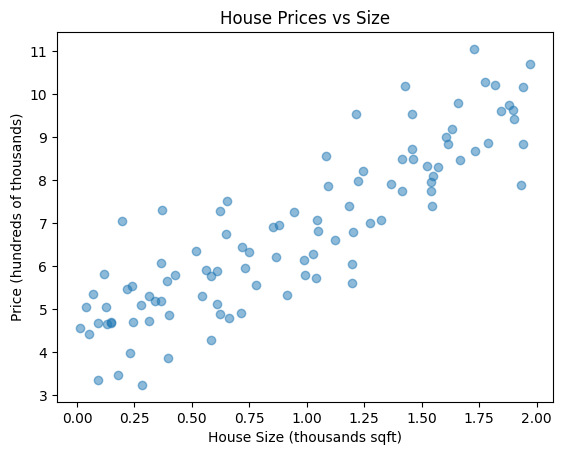

In [3]:
plt.scatter(X, y, alpha=0.5)
plt.xlabel("House Size (thousands sqft)")
plt.ylabel("Price (hundreds of thousands)")
plt.title("House Prices vs Size")
plt.show()

Now here's the core idea of linear regression:

We want to find a line y = mx + b that best fits this data. In ML terms:

m = weight (slope)
b = bias (intercept)

We know the true values are m=3, b=4 (we built the data that way). But pretend we don't know — we'll use gradient descent to find them.

In [4]:
# Initialize weights randomly
m = np.random.randn()
b = np.random.randn()

In [5]:
print(f"Starting m: {m:.4f}")
print(f"Starting b: {b:.4f}")

Starting m: 0.0130
Starting b: 1.4535


In [6]:
learning_rate = 0.1
n_iterations = 1000
n = len(X)
loss_history = []

In [7]:
for i in range(n_iterations):
    # Make predictions
    y_pred = m * X + b
    
    # Compute loss (MSE)
    loss = np.mean((y_pred - y) ** 2)
    loss_history.append(loss)
    
    # Compute gradients
    dm = (2/n) * np.sum((y_pred - y) * X)
    db = (2/n) * np.sum(y_pred - y)
    
    # Update weights
    m = m - learning_rate * dm
    b = b - learning_rate * db
    
    if i % 100 == 0:
        print(f"Iteration {i}: loss={loss:.4f}, m={m:.4f}, b={b:.4f}")

print(f"\nFinal: m={m:.4f}, b={b:.4f}")

Iteration 0: loss=32.1386, m=1.2132, b=2.5244
Iteration 100: loss=0.8066, m=2.7751, b=4.2095
Iteration 200: loss=0.8066, m=2.7703, b=4.2149
Iteration 300: loss=0.8066, m=2.7701, b=4.2151
Iteration 400: loss=0.8066, m=2.7701, b=4.2151
Iteration 500: loss=0.8066, m=2.7701, b=4.2151
Iteration 600: loss=0.8066, m=2.7701, b=4.2151
Iteration 700: loss=0.8066, m=2.7701, b=4.2151
Iteration 800: loss=0.8066, m=2.7701, b=4.2151
Iteration 900: loss=0.8066, m=2.7701, b=4.2151

Final: m=2.7701, b=4.2151


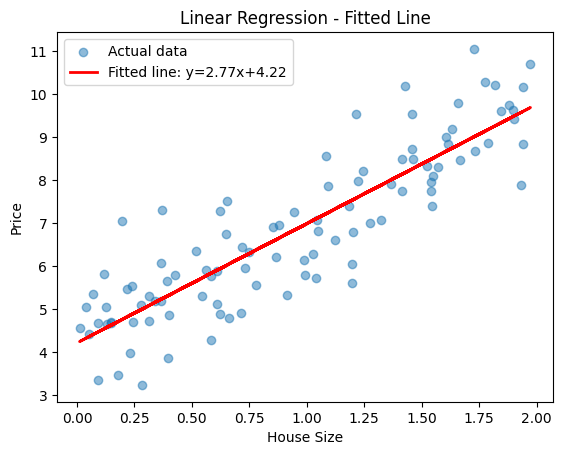

In [8]:
plt.scatter(X, y, alpha=0.5, label='Actual data')
plt.plot(X, m * X + b, color='red', linewidth=2, label=f'Fitted line: y={m:.2f}x+{b:.2f}')
plt.xlabel("House Size")
plt.ylabel("Price")
plt.title("Linear Regression - Fitted Line")
plt.legend()
plt.show()

Think about what just happened:

Started with random weights (m=0.013, b=1.45)
Ran gradient descent 1000 times
Model figured out m≈2.77, b≈4.21 purely from data
Red line fits the data well

That's machine learning in its purest form — a model learning patterns from data by minimizing error.

Let's plot the loss curve too to see the learning process:

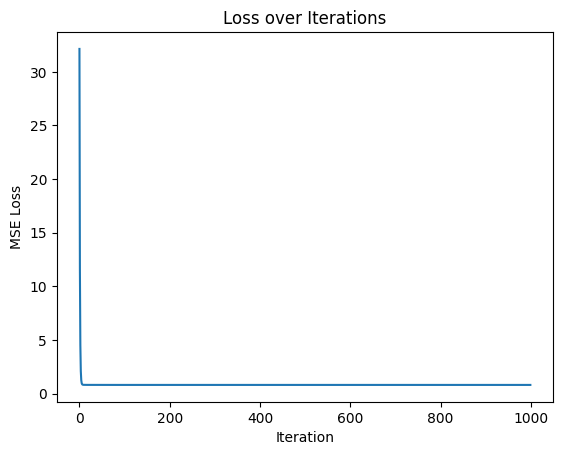

In [9]:
plt.plot(loss_history)
plt.title("Loss over Iterations")
plt.xlabel("Iteration")
plt.ylabel("MSE Loss")
plt.show()

A complete linear regression model from scratch:

✅ Generated data
✅ Initialized random weights
✅ Computed predictions
✅ Measured loss (MSE)
✅ Computed gradients
✅ Updated weights via gradient descent
✅ Visualized fitted line and loss curve

This is the foundation every other ML model builds on — neural networks are just many of these linear regressions stacked together with non-linearities added.

In [10]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X, y)

print(f"sklearn m: {model.coef_[0][0]:.4f}")
print(f"sklearn b: {model.intercept_[0]:.4f}")

sklearn m: 2.7701
sklearn b: 4.2151


Linear regression finds the best fitting line through data to predict a continuous output (like house price) from one or more inputs (like house size).

The slope and intercept are the result, not the problem being solved.

The loss function measures how wrong the model's predictions are at any given moment — one number summarizing total error across all data points.

Gradient descent is what minimizes the loss. The loss function just measures it.

Gradient descent iteratively adjusts the weights (m and b) in small steps, each time moving in the direction that reduces the loss, until the loss stops improving.

The simple version of all three together:

Linear regression: find the best line to predict y from x

Loss function: measure how bad current predictions are

Gradient descent: keep adjusting weights until predictions are as good as possible